In [ ]:
import marimo as mo
import pandas as pd
import numpy as np

In [ ]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


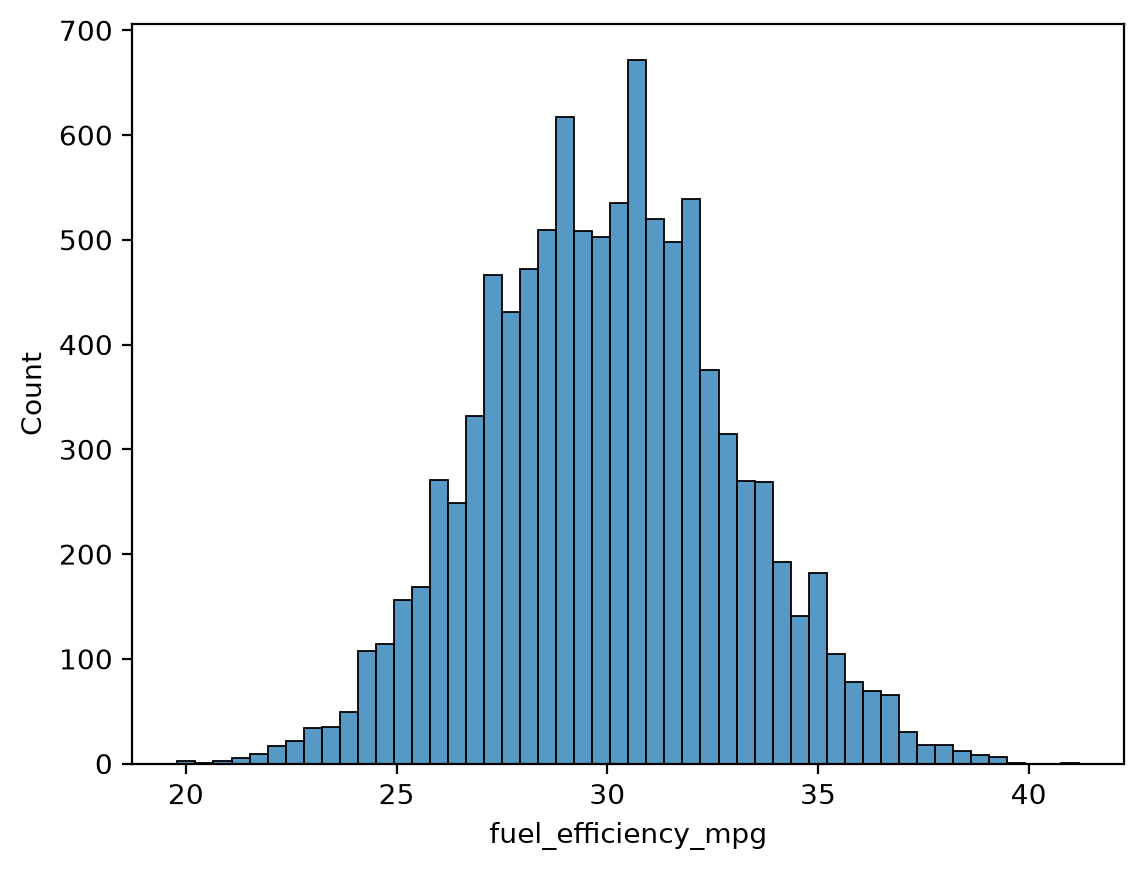

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["fuel_efficiency_mpg"], bins=50)

## Question 1 - There's one column with missing values. What is it?

In [ ]:
df.isnull().sum()

,0
engine_displacement,0
horsepower,877
vehicle_weight,0
model_year,0
fuel_efficiency_mpg,0


## Question 2 - What's the median (50% percentile) for variable 'horsepower'?

In [ ]:
df["horsepower"].median()

np.float64(254.0)

In [ ]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [ ]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [ ]:
def prepare_validation_framework(df: pd.DataFrame, seed: int, fill_method: str):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_train = df_train.copy()
    df_val = df_val.copy()
    df_test = df_test.copy()

    if fill_method == "with_0":
        fill_value = 0
    else:
        fill_value = df_train["horsepower"].mean()

    for split in (df_train, df_val, df_test):
        split["horsepower"] = split["horsepower"].fillna(fill_value)

    return df_train, df_val, df_test

### with 0

In [ ]:
df_train_0, df_val_0, _ = prepare_validation_framework(df, seed=42, fill_method="with_0")
X_train_0 = df_train_0.drop(columns="fuel_efficiency_mpg").to_numpy()
y_train_0 = df_train_0["fuel_efficiency_mpg"].to_numpy()
X_val_0 = df_val_0.drop(columns="fuel_efficiency_mpg").to_numpy()
y_val_0 = df_val_0["fuel_efficiency_mpg"].to_numpy()

intercept_0, weights_0 = train_linear_regression(X_train_0, y_train_0)
y_pred_0 = intercept_0 + X_val_0.dot(weights_0)
rmse_with_0 = round(rmse(y_val_0, y_pred_0), 3)
rmse_with_0

np.float64(2.205)

### with mean

In [ ]:
df_train_mean, df_val_mean, _ = prepare_validation_framework(df, seed=42, fill_method="with_mean")
X_train_mean = df_train_mean.drop(columns="fuel_efficiency_mpg").to_numpy()
y_train_mean = df_train_mean["fuel_efficiency_mpg"].to_numpy()
X_val_mean = df_val_mean.drop(columns="fuel_efficiency_mpg").to_numpy()
y_val_mean = df_val_mean["fuel_efficiency_mpg"].to_numpy()

intercept_mean, weights_mean = train_linear_regression(X_train_mean, y_train_mean)
y_pred_mean = intercept_mean + X_val_mean.dot(weights_mean)
rmse_with_mean = round(rmse(y_val_mean, y_pred_mean), 3)
rmse_with_mean

np.float64(2.202)

### Question 3 - Which option gives better RMSE?

In [ ]:
better_option = "With 0" if rmse_with_0 < rmse_with_mean else "With mean" if rmse_with_mean < rmse_with_0 else "Both are equally good"
mo.md(f"RMSE with 0: **{rmse_with_0}**  \nRMSE with mean: **{rmse_with_mean}**  \nBetter option: **{better_option}**")

RMSE with 0: **2.205**  
RMSE with mean: **2.202**  
Better option: **With mean**

## Question 4 - Which r gives the best RMSE?

In [ ]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [ ]:
df_train_reg, df_val_reg, _ = prepare_validation_framework(df, seed=42, fill_method="with_0")
X_train_reg = df_train_reg.drop(columns="fuel_efficiency_mpg").to_numpy()
y_train_reg = df_train_reg["fuel_efficiency_mpg"].to_numpy()
X_val_reg = df_val_reg.drop(columns="fuel_efficiency_mpg").to_numpy()
y_val_reg = df_val_reg["fuel_efficiency_mpg"].to_numpy()

regularization_values = [0, 0.01, 0.1, 1, 5, 10, 100]
rmse_by_r = {}
for regularization_value in regularization_values:
    intercept_reg, weights_reg = train_linear_regression_reg(
        X_train_reg, y_train_reg, r=regularization_value
    )
    y_pred_reg = intercept_reg + X_val_reg.dot(weights_reg)
    rmse_by_r[regularization_value] = round(rmse(y_val_reg, y_pred_reg), 4)

best_r = min(regularization_values, key=lambda value: (rmse_by_r[value], value))
rmse_by_r, best_r

## Question 5 - How does the seed influence the score?

In [ ]:
seed_values = list(range(10))
rmse_by_seed = {}

for seed_value in seed_values:
    df_train_seed, df_val_seed, _ = prepare_validation_framework(df, seed=seed_value, fill_method="with_0")
    X_train_seed = df_train_seed.drop(columns="fuel_efficiency_mpg").to_numpy()
    y_train_seed = df_train_seed["fuel_efficiency_mpg"].to_numpy()
    X_val_seed = df_val_seed.drop(columns="fuel_efficiency_mpg").to_numpy()
    y_val_seed = df_val_seed["fuel_efficiency_mpg"].to_numpy()

    intercept_seed, weights_seed = train_linear_regression(X_train_seed, y_train_seed)
    y_pred_seed = intercept_seed + X_val_seed.dot(weights_seed)
    rmse_by_seed[seed_value] = rmse(y_val_seed, y_pred_seed)

std_rmse = round(np.std(list(rmse_by_seed.values())), 3)
rmse_by_seed, std_rmse

In [ ]:
mo.md(f"""
RMSE by seed: **{rmse_by_seed}**  \nStandard deviation: **{std_rmse}**
""")

RMSE by seed: **{0: np.float64(2.2392041430461465), 1: np.float64(2.2021128210838907), 2: np.float64(2.163419778753095), 3: np.float64(2.2043588768539144), 4: np.float64(2.2018800943312926), 5: np.float64(2.2457851509084974), 6: np.float64(2.269721207952404), 7: np.float64(2.190794599933433), 8: np.float64(2.2166112016864443), 9: np.float64(2.207036592817851)}**  
Standard deviation: **0.029**

## Question 6 - What is the RMSE on the test dataset?

In [ ]:
df_train_q6, df_val_q6, df_test_q6 = prepare_validation_framework(df, seed=9, fill_method="with_0")

X_train_q6 = df_train_q6.drop(columns="fuel_efficiency_mpg").to_numpy()
y_train_q6 = df_train_q6["fuel_efficiency_mpg"].to_numpy()
X_val_q6 = df_val_q6.drop(columns="fuel_efficiency_mpg").to_numpy()
y_val_q6 = df_val_q6["fuel_efficiency_mpg"].to_numpy()
X_test_q6 = df_test_q6.drop(columns="fuel_efficiency_mpg").to_numpy()
y_test_q6 = df_test_q6["fuel_efficiency_mpg"].to_numpy()

X_train_val_q6 = np.concatenate([X_train_q6, X_val_q6])
y_train_val_q6 = np.concatenate([y_train_q6, y_val_q6])

intercept_q6, weights_q6 = train_linear_regression_reg(X_train_val_q6, y_train_val_q6, r=0.001)
y_pred_test_q6 = intercept_q6 + X_test_q6.dot(weights_q6)
rmse_test_q6 = round(rmse(y_test_q6, y_pred_test_q6), 3)
rmse_test_q6

np.float64(2.236)